# 05 · Height validation against G-LiHT, by height class

**Question:** are reclassified 30 m heights closer to G-LiHT than the current v7 segments, across height classes from tundra
shrubs to tall Kenai forest?

Reference for each segment: the 1 m G-LiHT CHM inside the segment footprint (30 m along track × 11 m), after the track's
horizontal shift from notebook 02. Main reference metric: CHM 98th percentile (RH98, config `validation.als_reference_percentile`);
RH90–RH100 are also compared because the best-matching ALS percentile for ICESat-2 is not fixed (Zhang & Liu 2023 found RH95).
Segments with > 10 % disturbed photons (Hansen loss in or after the ALS year) are excluded. Seward segments (UAV reference,
notebook 01) are added for the 0–2 m classes.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.2.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.2 fc2468cc8841 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.2


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7e530f1",
 "git_dirty_lib_or_config": true,
 "config_version": "0.2",
 "config_sha1": "fc2468cc8841",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T18:10:03"
}


## Reference height for every segment

**Input:** the matched segments (notebook 04), the G-LiHT CHM strips and the track shifts (notebook 02).

**What happens:** each segment becomes a footprint rectangle (first to last photon, 11 m wide), shifted by its track's
horizontal offset; the 1 m CHM values inside it give the **reference height** (CHM RH98) and other percentiles and cover
fractions (`lib: segment_footprints, als_segment_metrics`). Segments with more than 10 % disturbed photons are dropped.
Seward segments (UAV reference, notebook 01) are added.

**Output:** `validation/tile_<n>_segments_als.parquet`.

In [2]:
GL = WORK / "glihit"; GLV = RUN / "glihit"; SEG = RUN / "segments"; OUT = RUN / "validation"; OUT.mkdir(exist_ok=True)
parts = []
for fn in sorted(SEG.glob("tile_*_segments.parquet")):
    t = int(fn.name.split("_")[1])
    s = gpd.read_parquet(fn)
    fpo = OUT / f"tile_{t}_segments_als.parquet"
    if fpo.exists():
        parts.append(gpd.read_parquet(fpo)); continue
    strips = pd.read_csv(GL / f"tile_{t}" / "strips.csv")
    off = pd.read_csv(GLV / f"tile_{t}" / "offsets.csv").set_index("track_id")
    fps = ref.segment_footprints(s, cfg["validation"]["segment_footprint_width_m"])
    out = []
    for tid, g in fps.groupby("track_id"):
        dx, dy = (off.loc[tid, "dx"], off.loc[tid, "dy"]) if tid in off.index else (0.0, 0.0)
        out.append(ref.als_segment_metrics(g, strips.chm.tolist(), dx, dy, percentiles=(50, 75, 90, 95, 98, 100)))
    a = gpd.GeoDataFrame(pd.concat(out), crs=fps.crs).to_crs(4326)
    ipl.write_parquet(a, fpo, ipl.provenance(cfg, tile_num=t))
    parts.append(a)
v = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
v = v[(v.als_n > 0) & (v.disturbed_frac.fillna(0) <= 0.10)]
sew = pd.concat([gpd.read_parquet(f) for f in sorted((RUN / "seward").glob("*_segments.parquet"))], ignore_index=True)
sew = sew[sew.als_n > 0].assign(region="Seward")
val_all = pd.concat([v, sew], ignore_index=True)
print(val_all.groupby("region").size())

region
Interior    18698
Kenai        7259
Seward        483
dtype: int64


## Which G-LiHT height percentile does each version track?

`h_canopy` is the 98th percentile of canopy photons, but sparse photons rarely hit the very top of the canopy, so ICESat-2
heights may match a lower percentile of the lidar CHM (Zhang & Liu 2023 found RH95). Bias, RMSE and correlation of each 30 m
version against the CHM RH90, RH95, RH98 and RH100 inside the segment footprints.

In [3]:
schemes = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08", val.LABEL_NEW: "h_canopy"}
rows = []
for k, c in schemes.items():
    for p in (90, 95, 98, 100):
        d = val_all[[c, f"als_rh{p}"]].dropna()
        e = d[c] - d[f"als_rh{p}"]
        rows.append({"scheme": k, "als": f"RH{p}", "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r": d.corr().iat[0, 1]})
pd.DataFrame(rows).pivot(index="als", columns="scheme", values=["bias", "rmse", "r"]).round(2)

bias  \
scheme ATL08 classes → our 30 m (check)   
als                                       
RH100                              0.83   
RH90                               3.50   
RH95                               2.76   
RH98                               2.02   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                      -0.93   
RH90                                        1.42   
RH95                                        0.78   
RH98                                        0.13   

                                                                         rmse  \
scheme reclassified photons → our 30 m (new) ATL08 classes → our 30 m (check)   
als                                                                             
RH100                                  -0.46                             7.66   
RH90                                    1.66                             7.39   
RH95                                    1.08                             7.32   
RH98                                    0.51                             7.39   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                       8.08   
RH90                                        7.35   
RH95                                        7.42   
RH98                                        7.61   

                                                                            r  \
scheme reclassified photons → our 30 m (new) ATL08 classes → our 30 m (check)   
als                                                                             
RH100                                   6.59                             0.42   
RH90                                    6.05                             0.47   
RH95                                    6.09                             0.46   
RH98                                    6.22                             0.44   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                       0.42   
RH90                                        0.45   
RH95                                        0.45   
RH98                                        0.44   

                                              
scheme reclassified photons → our 30 m (new)  
als                                           
RH100                                   0.58  
RH90                                    0.62  
RH95                                    0.61  
RH98                                    0.59

## Error by reference height class (reference height = G-LiHT/UAV CHM RH98 in the footprint)

Top: each 30 m version against the reference height. Bottom: mean bias and RMSE per reference-height class, and the
spurious-vegetation rate (reference < 1 m, ICESat-2 > 2 m). In the reclassified version, segments set to 0 m by the
short-vegetation guard count as 0 m here.

n   bias  \
scheme                                    height_class                       
current v7 30 m (ATL08 classes → PhoREAL) 0-1 m              1074.0  3.373   
                                          1-2 m               280.0  1.619   
                                          2-5 m               430.0  0.769   
                                          5-10 m              370.0 -1.233   
                                          10-15 m             266.0 -3.691   
                                          15-20 m             282.0 -5.052   
                                          20+ m               135.0 -8.751   
                                          all                2837.0  0.128   
                                          spurious_veg_rate  1074.0  0.383   
ATL08 classes → our 30 m (check)          0-1 m               661.0  7.266   
                                          1-2 m               224.0  5.042   
                                          2-5 m               396.0  2.192   
                                          5-10 m              340.0  0.503   
                                          10-15 m             258.0 -2.152   
                                          15-20 m             278.0 -3.519   
                                          20+ m               131.0 -6.219   
                                          all                2288.0  2.021   
                                          spurious_veg_rate   661.0  0.694   
reclassified photons → our 30 m (new)     0-1 m               853.0  2.595   
                                          1-2 m               232.0  1.724   
                                          2-5 m               322.0  0.338   
                                          5-10 m              230.0 -1.605   
                                          10-15 m             181.0 -2.412   
                                          15-20 m             188.0 -2.911   
                                          20+ m                75.0 -4.071   
                                          all                2081.0  0.512   
                                          spurious_veg_rate   853.0  0.283   

                                                               rmse    mae  \
scheme                                    height_class                       
current v7 30 m (ATL08 classes → PhoREAL) 0-1 m               9.223  3.468   
                                          1-2 m               4.620  2.354   
                                          2-5 m               5.137  2.667   
                                          5-10 m              5.621  3.567   
                                          10-15 m             5.799  4.575   
                                          15-20 m             7.558  5.812   
                                          20+ m              11.827  9.005   
                                          all                 7.610  3.850   
                                          spurious_veg_rate     NaN    NaN   
ATL08 classes → our 30 m (check)          0-1 m               9.911  7.288   
                                          1-2 m               8.164  5.264   
                                          2-5 m               5.500  3.426   
                                          5-10 m              4.999  3.692   
                                          10-15 m             4.870  3.699   
                                          15-20 m             5.469  4.043   
                                          20+ m               8.823  6.418   
                                          all                 7.390  5.038   
                                          spurious_veg_rate     NaN    NaN   
reclassified photons → our 30 m (new)     0-1 m               6.474  2.841   
                                          1-2 m               6.732  3.081   
                                          2-5 m               4.917  3.074   
         

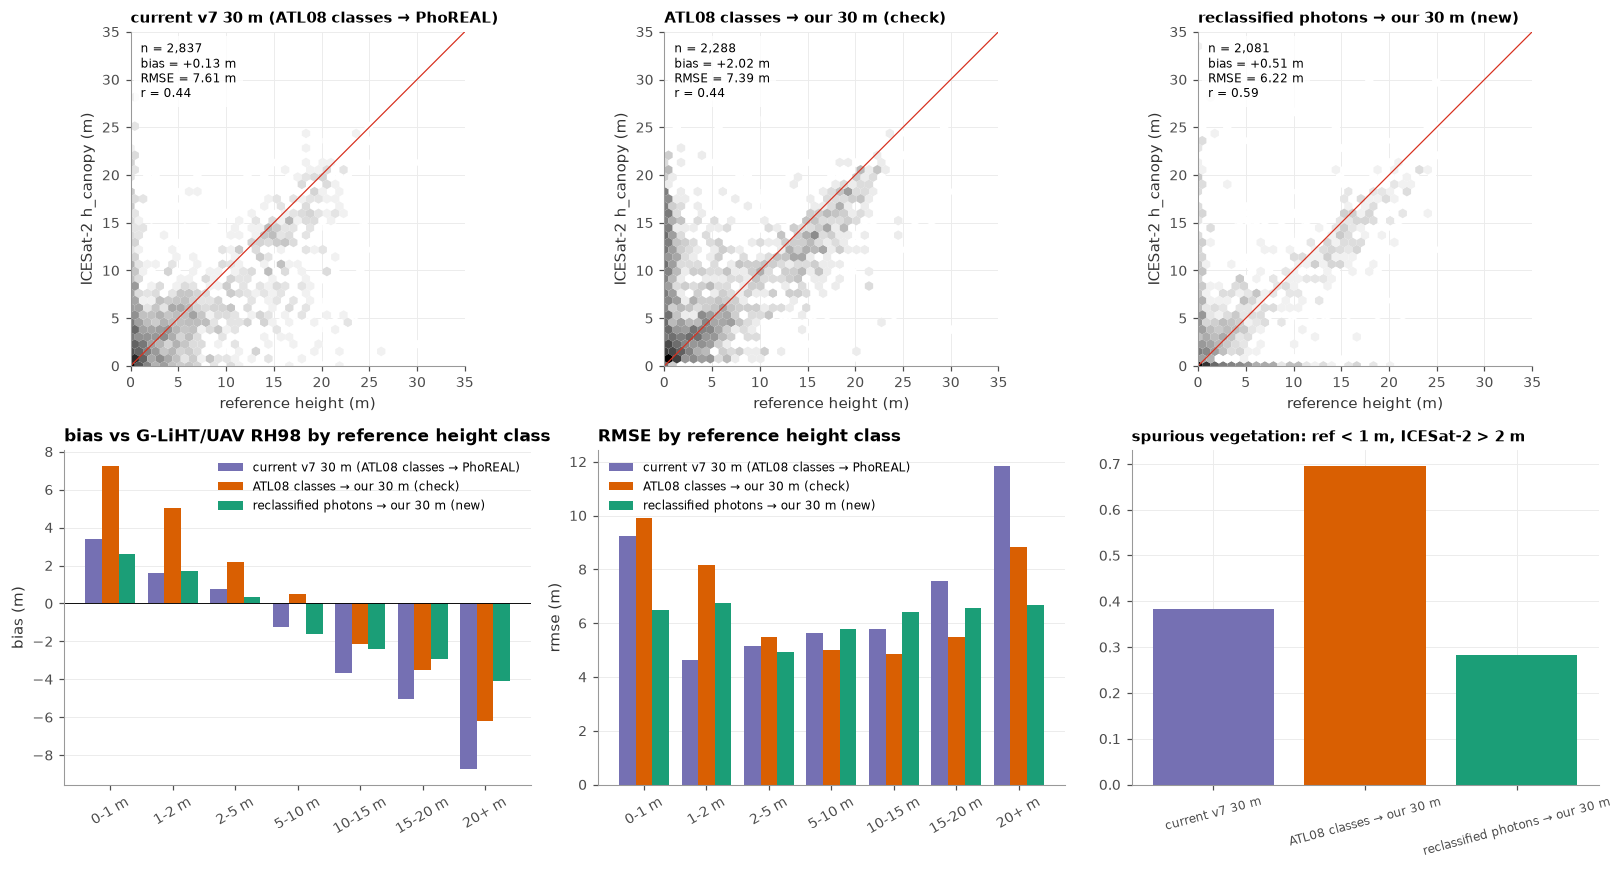

In [4]:
edges = cfg["validation"]["height_classes_m"]
REF = f"als_rh{cfg['validation']['als_reference_percentile']}"
tabs = {k: val.metrics_by_height_class(val_all[c], val_all[REF], edges, cfg["validation"]["spurious_veg"]) for k, c in schemes.items()}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (k, c) in zip(axes[0], schemes.items()):
    val.plot_scatter(ax, val_all[c], val_all[REF], k, lim=35)
val.plot_bias_by_class(tabs, f"bias vs G-LiHT/UAV {REF.upper()[4:]} by reference height class", axes[1, 0], "bias")
val.plot_bias_by_class(tabs, "RMSE by reference height class", axes[1, 1], "rmse")
sp = pd.Series({k: t.loc["spurious_veg_rate", "bias"] for k, t in tabs.items()})
axes[1, 2].bar(range(len(sp)), sp.values, color=[val.SCHEME_COLORS[k] for k in sp.index])
axes[1, 2].set_xticks(range(len(sp)), [k.split(" (")[0] for k in sp.index], rotation=15, fontsize=8)
axes[1, 2].set_title("spurious vegetation: ref < 1 m, ICESat-2 > 2 m", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "05_height_validation.png", dpi=150)
summary = pd.concat(tabs, names=["scheme", "height_class"]).round(3)
summary.to_csv(OUT / "height_validation_by_class.csv")
summary

## By region, day vs night, and beam strength

Mean bias of each 30 m version against the reference height, split by region (Interior, Kenai, Seward), by solar elevation,
and by beam strength.

bias  \
scheme          ATL08 classes → our 30 m (check)   
by     group                                       
beam   strong                               1.51   
       weak                                 2.94   
light  day                                  2.95   
       night                               -0.13   
region Interior                             2.45   
       Kenai                                0.57   
       Seward                               4.81   

                                                           \
scheme          current v7 30 m (ATL08 classes → PhoREAL)   
by     group                                                
beam   strong                                        0.44   
       weak                                         -0.39   
light  day                                          -0.35   
       night                                         1.16   
region Interior                                     -0.05   
       Kenai                                        -0.39   
       Seward                                        2.11   

                                                       \
scheme          reclassified photons → our 30 m (new)   
by     group                                            
beam   strong                                    0.99   
       weak                                     -1.30   
light  day                                       0.65   
       night                                     0.19   
region Interior                                  0.09   
       Kenai                                     0.64   
       Seward                                    1.26   

                                            rmse  \
scheme          ATL08 classes → our 30 m (check)   
by     group                                       
beam   strong                               6.56   
       weak                                 8.70   
light  day                                  7.78   
       night                                6.41   
region Interior                             7.32   
       Kenai                                7.38   
       Seward                               7.54   

                                                           \
scheme          current v7 30 m (ATL08 classes → PhoREAL)   
by     group                                                
beam   strong                                        6.84   
       weak                                          8.75   
light  day                                           6.35   
       night                                         9.80   
region Interior                                      5.71   
       Kenai                                         9.58   
       Seward                                        4.54   

                                                       
scheme          reclassified photons → our 30 m (new)  
by     group                                           
beam   strong                                    6.38  
       weak                                      5.59  
light  day                                       6.48  
       night                                     5.57  
region Interior                                  5.97  
       Kenai                                     6.97  
       Seward                                    4.37

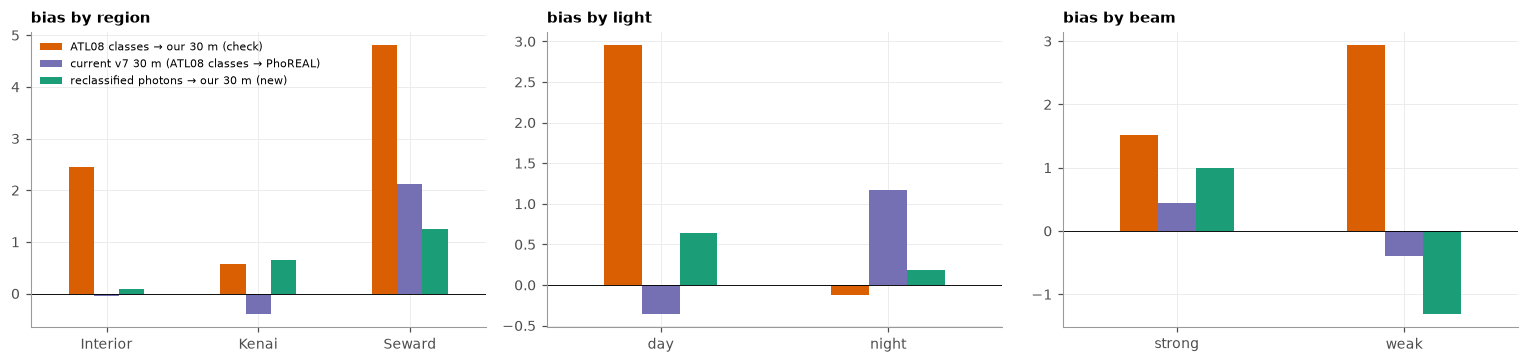

In [5]:
val_all["light"] = np.where(val_all.solar_elevation > 0, "day", "night")
val_all["beam"] = np.where(val_all.strong, "strong", "weak")
rows = []
for by in ["region", "light", "beam"]:
    for grp, g in val_all.groupby(by):
        for k, c in schemes.items():
            d = g[[c, REF]].dropna(); e = d[c] - d[REF]
            rows.append({"by": by, "group": grp, "scheme": k, "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean())})
t = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, by in zip(axes, ["region", "light", "beam"]):
    tt = t[t.by == by].pivot(index="group", columns="scheme", values="bias")
    tt.plot.bar(ax=ax, color=[val.SCHEME_COLORS[c] for c in tt.columns], legend=(by == "region"), rot=0)
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"bias by {by}", loc="left", fontsize=10); ax.set_xlabel("")
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "05_bias_by_group.png", dpi=150)
t.pivot_table(index=["by", "group"], columns="scheme", values=["bias", "rmse"]).round(2)

## By signal strength: day/night × beam

The shift scan (LOG, 15 Oct) showed that footprint placement does not explain the low pooled agreement; signal does (r ≈ 0.6 at
night, ≈ 0.5 on strong beams). Every version is therefore also reported in the four signal strata: night strong, night weak,
day strong, day weak. A version that only looks good in the pooled numbers because of the mix of strata is not an improvement.

bias  \
scheme         ATL08 classes → our 30 m (check)   
stratum                                           
night · strong                             0.33   
night · weak                              -1.36   
day · strong                               2.13   
day · weak                                 4.22   

                                                          \
scheme         current v7 30 m (ATL08 classes → PhoREAL)   
stratum                                                    
night · strong                                      1.87   
night · weak                                       -0.39   
day · strong                                       -0.32   
day · weak                                         -0.39   

                                                      \
scheme         reclassified photons → our 30 m (new)   
stratum                                                
night · strong                                  0.46   
night · weak                                   -1.29   
day · strong                                    1.23   
day · weak                                     -1.31   

                                              n  \
scheme         ATL08 classes → our 30 m (check)   
stratum                                           
night · strong                            506.0   
night · weak                              187.0   
day · strong                              967.0   
day · weak                                628.0   

                                                          \
scheme         current v7 30 m (ATL08 classes → PhoREAL)   
stratum                                                    
night · strong                                     618.0   
night · weak                                       279.0   
day · strong                                      1157.0   
day · weak                                         783.0   

                                                      \
scheme         reclassified photons → our 30 m (new)   
stratum                                                
night · strong                                 512.0   
night · weak                                    95.0   
day · strong                                  1135.0   
day · weak                                     339.0   

                                              r  \
scheme         ATL08 classes → our 30 m (check)   
stratum                                           
night · strong                             0.63   
night · weak                               0.55   
day · strong                               0.52   
day · weak                                 0.17   

                                                          \
scheme         current v7 30 m (ATL08 classes → PhoREAL)   
stratum                                                    
night · strong                                      0.48   
night · weak                                        0.25   
day · strong                                        0.63   
day · weak                                          0.24   

                                                      \
scheme         reclassified photons → our 30 m (new)   
stratum                                                
night · strong                                  0.70   
night · weak                                    0.53   
day · strong                                    0.57   
day · weak                                      0.29   

                                           rmse  \
scheme         ATL08 classes → our 30 m (check)   
stratum                                           
night · strong                             6.42   
night · weak                               6.39   
day · strong                               6.63   
day · weak                                 9.27   

                                                          \
scheme         current v7 30 m (ATL08 classes → PhoREAL)   
stratum                                          

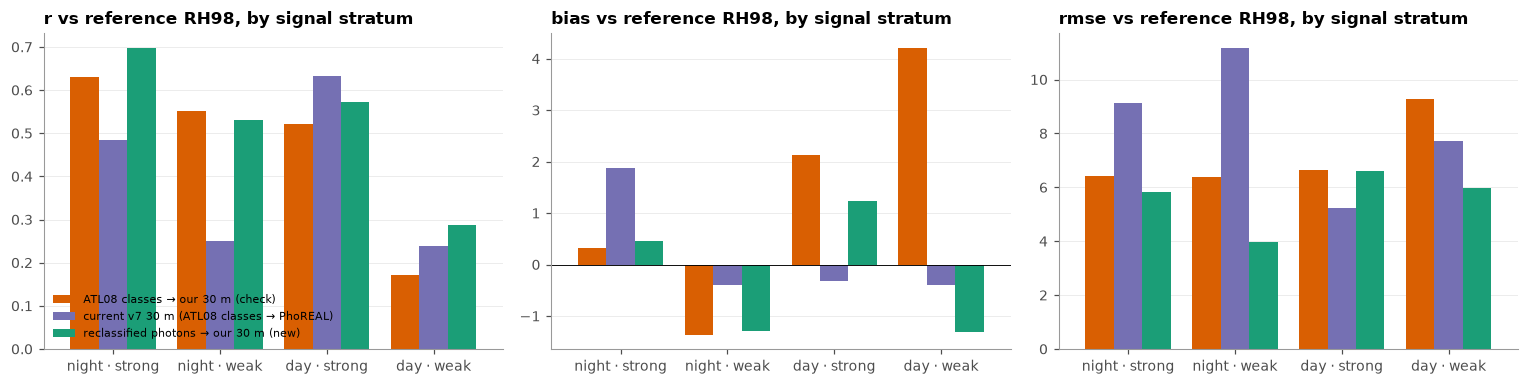

In [6]:
val_all["signal_stratum"] = val_all["light"] + " · " + val_all["beam"]
order = ["night · strong", "night · weak", "day · strong", "day · weak"]
rows = []
for st, g in val_all.groupby("signal_stratum"):
    for k, c in schemes.items():
        d = g[[c, REF]].dropna(); e = d[c] - d[REF]
        rows.append({"stratum": st, "scheme": k, "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()),
                     "r": d.corr().iat[0, 1] if len(d) > 2 else np.nan})
ts = pd.DataFrame(rows)
ts.to_csv(OUT / "height_validation_by_signal.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m in zip(axes, ["r", "bias", "rmse"]):
    tt = ts.pivot(index="stratum", columns="scheme", values=m).reindex(order)
    tt.plot.bar(ax=ax, color=[val.SCHEME_COLORS[c] for c in tt.columns], legend=(m == "r"), rot=0, width=0.8)
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"{m} vs reference {REF.upper()[4:]}, by signal stratum"); ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "05_by_signal.png")
ts.pivot_table(index="stratum", columns="scheme", values=["n", "r", "bias", "rmse"]).reindex(order).round(2)

## Compared with the previous config version, on common segments

Mean bias moves when a version reports heights for a different set of segments (for example v0.1 wrote 0 m where v0.2 reports
"not enough signal"), even if no height changed. So the previous version is compared here (a) on the segments **both** versions
report, by reference height class and region, and (b) by **coverage**: the share of segments that get a height at all.
Tall-forest acceptance (LOG, 15 Oct): in every class ≥ 10 m and every region, the new version's bias must be no more negative
than the current v7 30 m.

coverage: share of segments with a height


,previous (v0.1),this version (v0.2),current v7 30 m
region,,,
Interior,1.0,0.733,0.949
Kenai,1.0,0.666,0.887


bias                                      \
version               current v7 30 m previous (v0.1) this version (v0.2)   
region   height_class                                                       
Interior 0-1 m                   2.23            1.73                2.44   
         1-2 m                   0.68            0.32                0.59   
         10-15 m                -5.10           -6.55               -2.76   
         15-20 m                -9.02          -12.63               -7.93   
         2-5 m                  -0.65           -2.02               -1.24   
         20+ m                 -10.62          -14.51               -8.06   
         5-10 m                 -2.41           -4.61               -3.46   
         all                    -0.02           -0.95                0.07   
Kenai    0-1 m                   3.84            2.56                3.65   
         1-2 m                   6.40            3.07                5.10   
         10-15 m                -2.14           -6.07               -2.26   
         15-20 m                -3.87           -6.81               -2.48   
         2-5 m                   3.14           -0.17                2.40   
         20+ m                  -6.01           -8.50               -3.72   
         5-10 m                  0.49           -2.15                0.38   
         all                     0.32           -2.07                0.65   
all      0-1 m                   2.98            2.11                3.00   
         1-2 m                   1.62            0.89                1.53   
         10-15 m                -3.06           -6.22               -2.41   
         15-20 m                -4.29           -7.28               -2.91   
         2-5 m                   0.63           -1.38                0.01   
         20+ m                  -6.39           -8.99               -4.07   
         5-10 m                 -1.09           -3.42               -1.61   
         all                     0.15           -1.52                0.37   

                                    n                                      \
version               current v7 30 m previous (v0.1) this version (v0.2)   
region   height_class                                                       
Interior 0-1 m                  335.0           369.0               369.0   
         1-2 m                  131.0           137.0               137.0   
         10-15 m                 54.0            55.0                55.0   
         15-20 m                 15.0            15.0                15.0   
         2-5 m                  147.0           153.0               153.0   
         20+ m                    6.0             6.0                 6.0   
         5-10 m                 117.0           119.0               119.0   
         all                    805.0           854.0               854.0   
Kenai    0-1 m                  291.0           310.0               310.0   
         1-2 m                   26.0            36.0                36.0   
         10-15 m                120.0           126.0               126.0   
         15-20 m                167.0           173.0               173.0   
         2-5 m                   75.0            80.0                80.0   
         20+ m                   66.0            68.0                68.0   
         5-10 m                  98.0           111.0               111.0   
         all                    843.0           904.0               904.0   
all      0-1 m                  626.0           679.0               679.0   
         1-2 m                  157.0           173.0               173.0   
         10-15 m                174.0           181.0               181.0   
         15-20 m                182.0           188.0               188.0   
         2-5 m                  222.0           233.0               233.0   
         20+ m                   72.0            74.0                74.0   
         5-10 m             

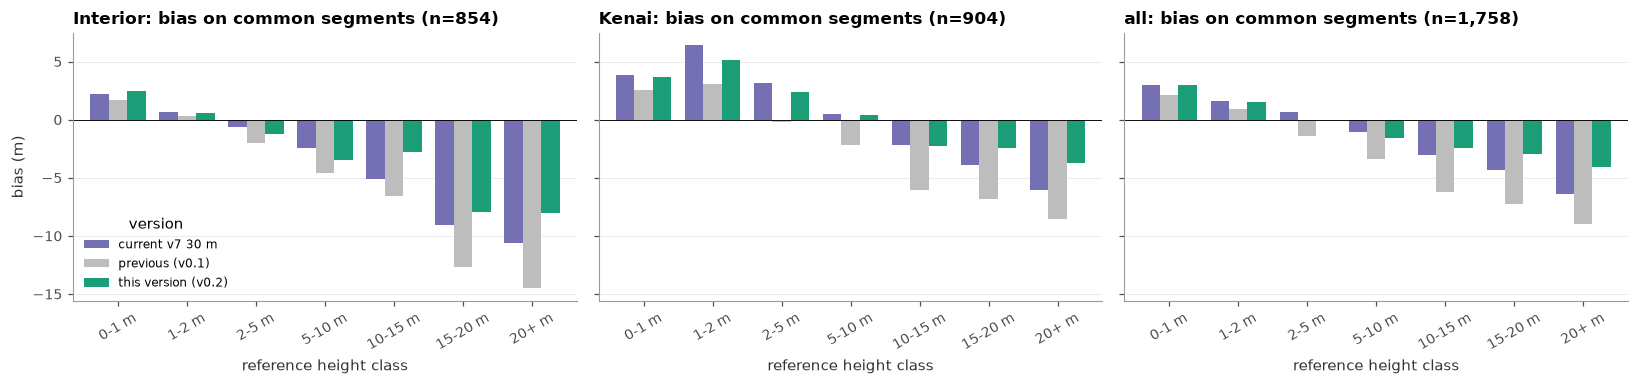

In [7]:
PREV = {"0.2": WORK / "validation"}.get(cfg["version"], WORK / "runs" / f"v{float(cfg['version']) - 0.1:.1f}" / "validation")  # v0.1 outputs predate runs/
prev = pd.concat([gpd.read_parquet(f) for f in sorted(PREV.glob("tile_*_segments_als.parquet"))], ignore_index=True)
prev = prev[(prev.als_n > 0) & (prev.disturbed_frac.fillna(0) <= 0.10)]
key = ["track_id", "seg"]
cur = v[key + ["region", "h_canopy", REF, "h_canopy_phoreal", "solar_elevation", "strong"]]
both = cur.merge(prev[key + ["h_canopy"]].rename(columns={"h_canopy": "h_prev"}), on=key, how="inner")
lab_prev, lab_cur = f"previous ({PREV.parent.name if PREV.parent.name.startswith('v') else 'v0.1'})", f"this version (v{cfg['version']})"
cov = pd.DataFrame({lab_prev: prev.groupby("region").h_canopy.apply(lambda s: s.notna().mean()),
                    lab_cur: cur.groupby("region").h_canopy.apply(lambda s: s.notna().mean()),
                    "current v7 30 m": cur.groupby("region").h_canopy_phoreal.apply(lambda s: s.notna().mean())}).round(3)
print("coverage: share of segments with a height"); display(cov)
common = both.dropna(subset=["h_canopy", "h_prev", REF])
rows = []
for reg, g in list(common.groupby("region")) + [("all", common)]:
    for nm, col in [(lab_prev, "h_prev"), (lab_cur, "h_canopy"), ("current v7 30 m", "h_canopy_phoreal")]:
        t = val.metrics_by_height_class(g[col], g[REF], edges)
        rows.append(t.assign(region=reg, version=nm))
cmp_tab = pd.concat(rows).reset_index(names="height_class")
cmp_tab.to_csv(OUT / "version_comparison_common_segments.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, reg in zip(axes, ["Interior", "Kenai", "all"]):
    tt = cmp_tab[(cmp_tab.region == reg) & ~cmp_tab.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))
    vcol = {lab_prev: "#bdbdbd", lab_cur: val.SCHEME_COLORS[val.LABEL_NEW], "current v7 30 m": val.SCHEME_COLORS[val.LABEL_CURRENT]}
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[vcol[c] for c in pv.columns])
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"{reg}: bias on common segments (n={int((common.region == reg).sum()) if reg != 'all' else len(common):,})")
    ax.set_xlabel("reference height class"); ax.set_ylabel("bias (m)"); ax.grid(axis="x", visible=False)
    if reg != "Interior": ax.get_legend().remove()
fig.tight_layout(); fig.savefig(FIG / "05_version_comparison.png")
cmp_tab.pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias", "rmse"]).round(2)

## Results
Summarise after review: bias and RMSE per height class for the three versions; the spurious-vegetation rate; whether the tall
classes are less underestimated after reclassification (acceptance criterion: in every class ≥ 10 m and every region, bias of
the new version no more negative than the current v7 30 m); differences by day/night × beam strength.